# Metrical BDI Analysis

This notebook performs authorship verification on metrical patterns using the BDI (Bootstrap Distance Imposters) algorithm from the [`bdi`](https://github.com/bnagy/bdi) package.

**Pipeline:**
1. Load metrical pattern data from CSV
2. Scale features (StandardScaler)
3. Run BDI verification with `minmax` metric (no feature selection)
4. Compare feature selection variants

In [2]:
import sys

sys.path.insert(0, "/Users/ben/code/bdi")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import logging

from sklearn.preprocessing import StandardScaler, LabelEncoder

from bdi import BDIVerifier

logging.basicConfig(level="INFO")
logger = logging.getLogger("bdi")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

Font name: `Roboto Condensed`


## Loading the data

In [4]:
raw_df = pd.read_csv("output.csv", encoding="utf-8")
print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors: {raw_df['Author'].nunique()} unique")
raw_df.head()

Loaded 659 rows, 24 columns
Authors: 40 unique


,Author,Work,Poem,1SP,2SP,3SP,4SP,1CF,2CF,3CF,...,4DI,1SC,2SC,3SC,4SC,1WC,2WC,3WC,4WC,ELC
0,AI,anticlaudianus,anticlaudianus - 1,0.380000,0.513333,0.620000,0.666667,0.280000,0.746667,0.820000,...,0.446667,0.360000,0.573333,0.840000,0.613333,0.166667,0.153333,0.160000,0.080000,0.000000
1,AI,anticlaudianus,anticlaudianus - 2,0.386667,0.586667,0.653333,0.813333,0.306667,0.700000,0.826667,...,0.493333,0.340000,0.540000,0.840000,0.633333,0.140000,0.193333,0.146667,0.020000,0.000000
2,AI,anticlaudianus,anticlaudianus - 3,0.293333,0.573333,0.520000,0.746667,0.260000,0.713333,0.886667,...,0.500000,0.326667,0.620000,0.880000,0.633333,0.180000,0.160000,0.100000,0.026667,0.000000
3,AI,anticlaudianus,anticlaudianus - 4,0.440000,0.480000,0.606667,0.820000,0.260000,0.700000,0.886667,...,0.433333,0.393333,0.600000,0.886667,0.660000,0.120000,0.153333,0.106667,0.046667,0.006667
4,AI,anticlaudianus,anticlaudianus - 5,0.353333,0.586667,0.593333,0.780000,0.226667,0.680000,0.846667,...,0.566667,0.380000,0.526667,0.846667,0.580000,0.173333,0.200000,0.133333,0.053333,0.000000


## Factorizing

The BDI code needs numeric labels. We use `LabelEncoder` to convert author names to integers.

In [6]:
print(raw_df["Author"].unique())

<ArrowStringArray>
[ 'AI', 'AeC', 'AeP',  'BC',   'B',  'DC',   'E',  'FB', 'GAp', 'GAr',  'GC',
  'GM',  'GP', 'GVS', 'GiP',  'HA',  'HP',   'H',  'IH',  'II',   'M', 'NLC',
  'OM', 'OSE',  'RC',  'RT',  'SG', 'U10', 'U11',  'U1',  'U2',  'U3',  'U4',
  'U5',  'U6',  'U7',  'U8',  'U9',  'X2',   'X']
Length: 40, dtype: str


In [7]:
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(raw_df["Author"])
raw_df.insert(1, "author_label", labels)

In [8]:
# Show label mapping
mapping = (
    raw_df[["Author", "author_label"]].drop_duplicates().sort_values("author_label")
)
print(mapping.to_string(index=False))
print(f"\nUnknown (X) label: {raw_df[raw_df['Author'] == 'X']['author_label'].iloc[0]}")

Author  author_label
    AI             0
   AeC             1
   AeP             2
     B             3
    BC             4
    DC             5
     E             6
    FB             7
   GAp             8
   GAr             9
    GC            10
    GM            11
    GP            12
   GVS            13
   GiP            14
     H            15
    HA            16
    HP            17
    IH            18
    II            19
     M            20
   NLC            21
    OM            22
   OSE            23
    RC            24
    RT            25
    SG            26
    U1            27
   U10            28
   U11            29
    U2            30
    U3            31
    U4            32
    U5            33
    U6            34
    U7            35
    U8            36
    U9            37
     X            38
    X2            39

Unknown (X) label: 38


## Scaling

Fit the scaler on all data, then transform. We use `StandardScaler(with_mean=False)` because the `minmax` metric needs non-negative scores.

In [10]:
numeric_cols = raw_df.select_dtypes(include=["number"]).columns
numeric_cols = numeric_cols[numeric_cols != "author_label"]

scaler = StandardScaler(with_mean=False).fit(raw_df[numeric_cols])
df_scaled = pd.DataFrame(scaler.transform(raw_df[numeric_cols]), columns=numeric_cols)
df_scaled["author_label"] = raw_df["author_label"].values

print(f"Scaled shape: {df_scaled.shape}")
df_scaled.head()

Scaled shape: (659, 22)


,1SP,2SP,3SP,4SP,1CF,2CF,3CF,4CF,1DI,2DI,...,1SC,2SC,3SC,4SC,1WC,2WC,3WC,4WC,ELC,author_label
0,3.057803,3.608619,4.960662,5.010757,3.078683,6.314177,5.706138,5.108329,5.878553,0.327223,...,3.729165,6.152448,7.010631,5.811795,3.561548,2.591227,1.997789,2.154310,0.000000,0
1,3.111449,4.124136,5.227364,6.113123,3.371891,5.919541,5.752529,5.401911,6.342649,0.163611,...,3.521990,5.794748,7.010631,6.001310,2.991700,3.267199,1.831306,0.538577,0.000000,0
2,2.360409,4.030406,4.160555,5.612048,2.858777,6.032294,6.170051,5.225762,5.491806,0.286320,...,3.383872,6.653229,7.344470,6.001310,3.846471,2.703889,1.248618,0.718103,0.000000,0
3,3.540614,3.374293,4.853981,6.163231,2.858777,5.919541,6.170051,5.578060,5.569155,0.286320,...,4.074459,6.438609,7.400110,6.253997,2.564314,2.591227,1.331859,1.256681,0.097591,0
4,2.843220,4.124136,4.747300,5.862585,2.492267,5.750411,5.891703,4.697314,5.878553,0.654445,...,3.936341,5.651667,7.066270,5.495937,3.704009,3.379861,1.664824,1.436206,0.000000,0


## Verification (no feature selection)

We hold out *De ordine* as the problem set and verify against all other authors using the `minmax` metric.

In [12]:
target_text = "ordine"

target_label = raw_df.loc[
    raw_df["Work"] == target_text,
    "author_label"
].iloc[0]

# Split into problem and comparison
problem_mask = raw_df["author_label"] == target_label

problem_X = df_scaled.loc[problem_mask].copy()
comparison_X = df_scaled.loc[~problem_mask].copy()

problem_y = problem_X["author_label"]
comparison_y = comparison_X["author_label"]

# Drop label column for verification
problem_X = problem_X.drop(columns=["author_label"])
comparison_X = comparison_X.drop(columns=["author_label"])

print(f"Problem: {problem_X.shape} | Comparison: {comparison_X.shape}")
print(f"Comparison authors: {sorted(raw_df.loc[~problem_mask, 'Author'].unique())}")

Problem: (3, 21) | Comparison: (656, 21)
Comparison authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9', 'X2']


In [13]:
rng = np.random.default_rng(42)

# Fit BDI verifier with minmax metric, no feature selection
bdi_mm = BDIVerifier(
    metric="minmax",
    nb_bootstrap_iter=1000,
    rnd_prop=0.35,
    random_state=rng,
)
bdi_mm.fit(comparison_X, comparison_y)

# Verify problem chunks against every candidate author
results = {}
for int_label in sorted(set(comparison_y)):
    str_label = label_encoder.classes_[int_label]
    print(f"...... Testing against: {str_label}")
    try:
        probas = bdi_mm.predict_proba(problem_X, [int_label] * problem_X.shape[0])
        results[str_label] = {"mean": np.mean(probas), "std": np.std(probas)}
        print(f"    Match strength: {np.mean(probas):.4f} ± {np.std(probas):.4f}")
    except Exception as e:
        print(f"    Error: {e}")

09/08/2026 01:45:30 [bdi:INFO] Fitting on 656 documents...
09/08/2026 01:45:30 [bdi:INFO] Predicting on 3 documents


...... Testing against: AI


09/08/2026 01:45:30 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:31 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.0123 ± 0.0068
...... Testing against: AeC
    Match strength: 0.0070 ± 0.0037
...... Testing against: AeP


09/08/2026 01:45:31 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:31 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:31 [bdi:INFO] Predicting on 3 documents


...

    Match strength: 0.9277 ± 0.0169
...... Testing against: U4
    Match strength: 0.5663 ± 0.0559
...... Testing against: U5


09/08/2026 01:45:34 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:34 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:34 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.0183 ± 0.0111
...... Testing against: U6
    Match strength: 0.3697 ± 0.0923
...... Testing against: U7
    Match strength: 0.1940 ± 0.0781
...... Testing against: U8


09/08/2026 01:45:34 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:34 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.0020 ± 0.0022
...... Testing against: U9
    Match strength: 0.0247 ± 0.0153
...... Testing against: X2
    Match strength: 0.7130 ± 0.1596


In [14]:
summary = pd.DataFrame(results).T
summary = summary.sort_values("mean", ascending=False)

summary.columns = [
    "Match Strength (mean)",
    "Match Strength (std)"
]

summary.index.name = "Candidate"

summary = summary.round(4)

display(summary)

,Match Strength (mean),Match Strength (std)
Candidate,,
U3,0.9277,0.0169
FB,0.7377,0.0170
X2,0.7130,0.1596
DC,0.6823,0.1087
U11,0.6530,0.0969
U4,0.5663,0.0559
M,0.4363,0.0635
HA,0.4280,0.0903
U6,0.3697,0.0923


/var/folders/ly/30xhvdxn4x3bm9847m7w6v080000gn/T/ipykernel_4148/2105876286.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


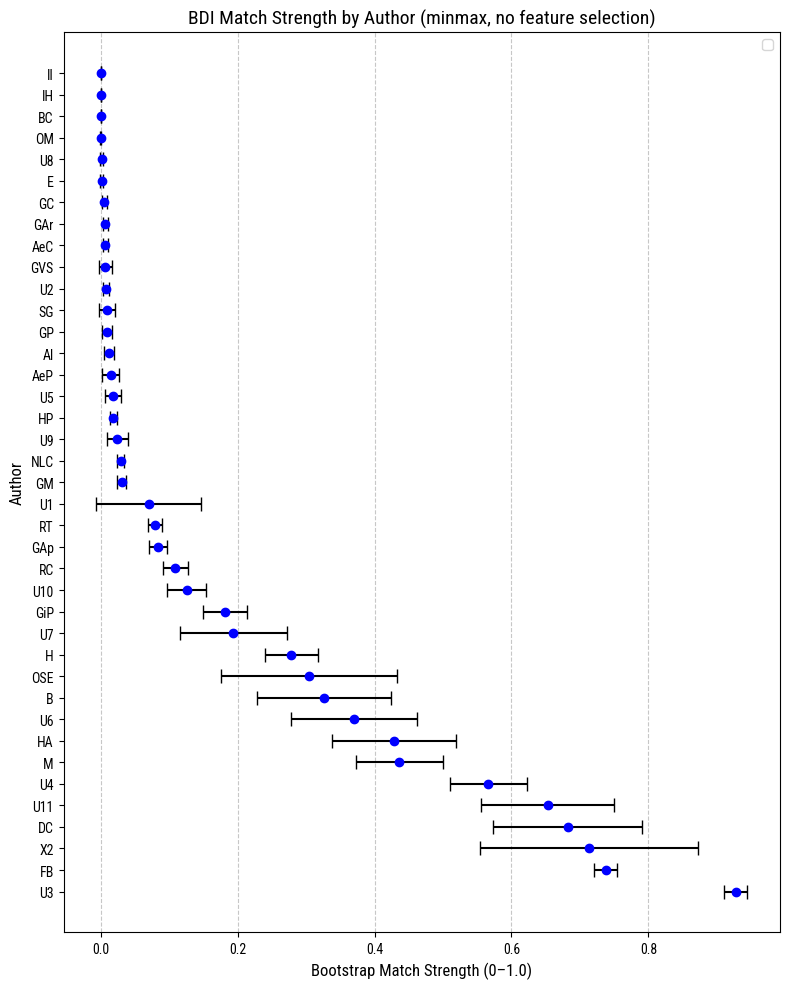

In [15]:
sorted_authors = sorted(results.items(), key=lambda x: x[1]["mean"], reverse=True)

labels_plot = [a[0] for a in sorted_authors]
means = [a[1]["mean"] for a in sorted_authors]
stds = [a[1]["std"] for a in sorted_authors]

fig, ax = plt.subplots(figsize=(8, 10))
ax.errorbar(
    means,
    labels_plot,
    xerr=stds,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
)
ax.set_xlabel("Bootstrap Match Strength (0–1.0)", fontsize=12)
ax.set_ylabel("Author", fontsize=12)
ax.set_title("BDI Match Strength by Author (minmax, no feature selection)", fontsize=14)
ax.grid(axis="x", linestyle="--", alpha=0.7)
ax.legend()
fig.tight_layout()
plt.savefig("forest_plot_minmax.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation

The 'match strength' is the bootstrap percentile of a metric distance of 0. Values over ~0.89 indicate high-precision matches (few false positives). Values below this threshold are *not* reliable negative indicators.

## Chunked Visualization

We can inspect the full bootstrap distance distribution per chunk using `_dist_arrays`. This shows the uncertainty in our determinations.

### Candidate: Hildebert (H)

In [18]:
label_index_H = label_encoder.transform(["H"])[0]

bdi_mm.predict_proba(problem_X, [label_index_H] * problem_X.shape[0])

ordine_vs_hildebert = pd.DataFrame(
    dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
)
ordine_vs_hildebert

09/08/2026 01:45:35 [bdi:INFO] Predicting on 3 documents


,656,657,658
0,-0.025466,-0.072167,-0.120834
1,-0.017698,-0.010233,-0.101141
2,0.020695,-0.006785,-0.084109
3,-0.072072,-0.115851,-0.055431
4,-0.066482,0.008633,0.014982
...,...,...,...
995,-0.006511,-0.011034,-0.001699
996,-0.111779,0.010066,-0.084692
997,0.002666,-0.069827,-0.002137
998,-0.119466,-0.046812,-0.090873


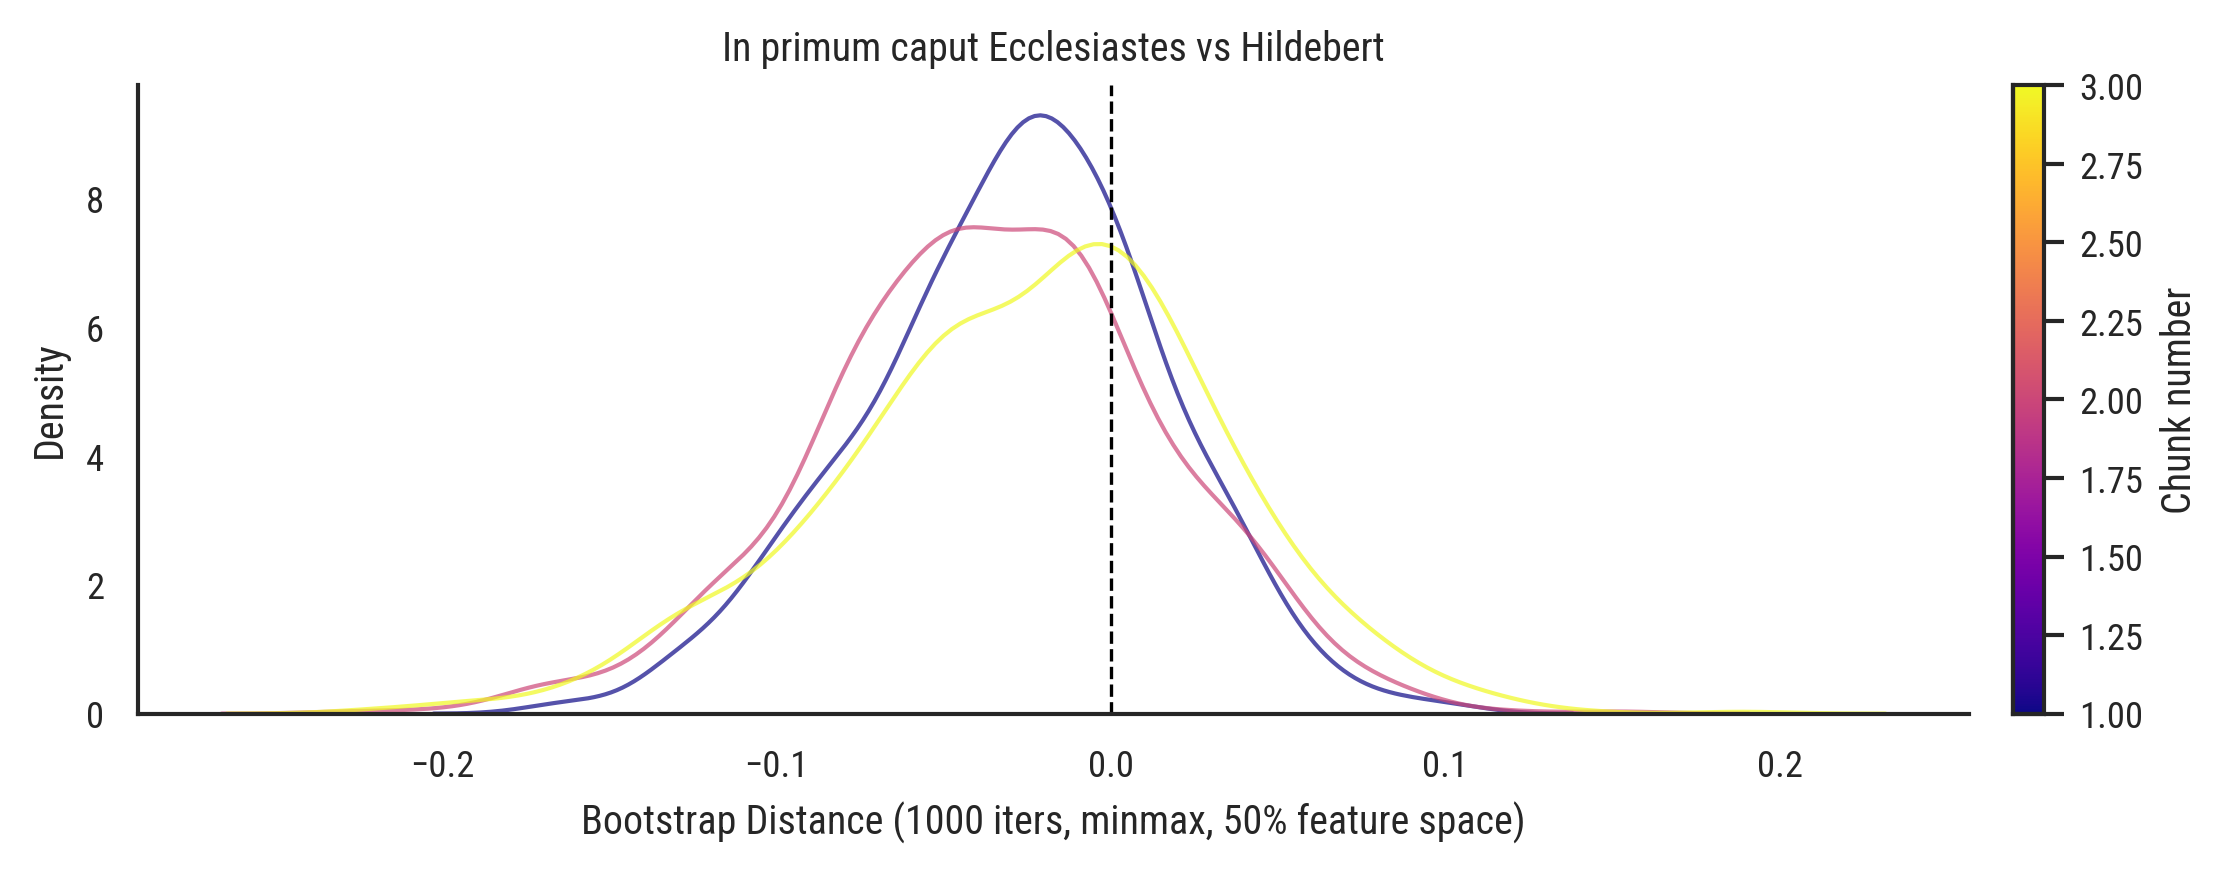

In [19]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re


def plot_kde_viridis(dist_df, poem_names, title="", xlabel="", ax=None):
    """Plot KDE curves colored by chunk number using viridis plasma.

    Later chunks (higher number in poem name) get darker colors.
    """
    # Extract chunk numbers from poem
    chunk_nums = []
    for idx in dist_df.columns:
        name = poem_names.loc[idx, "Poem"] if idx in poem_names.index else str(idx)
        m = re.search(r"(\d+)", name)
        chunk_nums.append(int(m.group(1)) if m else 0)

    chunk_nums = np.array(chunk_nums)
    n_chunks = len(chunk_nums)

    # Normalize chunk numbers to [0, 1] for colormap
    if chunk_nums.max() > chunk_nums.min():
        norm_vals = (chunk_nums - chunk_nums.min()) / (
            chunk_nums.max() - chunk_nums.min()
        )
    else:
        norm_vals = np.ones(n_chunks) * 0.5

    # Plasma: low values = bright/yellow, high values = dark/purple
    cmap = cm.plasma
    colors = [cmap(v) for v in norm_vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 3))

    for col, color in zip(dist_df.columns, colors):
        sns.kdeplot(dist_df[col], color=color, linewidth=1, alpha=0.7, ax=ax)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Density", title=title)

    # Add colorbar as legend
    sm = cm.ScalarMappable(
        cmap=cmap, norm=mcolors.Normalize(vmin=chunk_nums.min(), vmax=chunk_nums.max())
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Chunk number")

    return ax


poem_names = raw_df.loc[problem_mask]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
fig, ax = plt.subplots(figsize=(8, 3))
plot_kde_viridis(
ordine_vs_hildebert,
    poem_names,
    title="In primum caput Ecclesiastes vs Hildebert",
    xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
    ax=ax,
)
sns.despine()
fig.tight_layout()
plt.show()

NOTE: BDI match strengths favour precision (few false positives) and should not be interpreted as probabilities.

## Additional Candidates

We test several alternative candidates to compare their bootstrap distance distributions.

09/08/2026 01:45:36 [bdi:INFO] Predicting on 3 documents


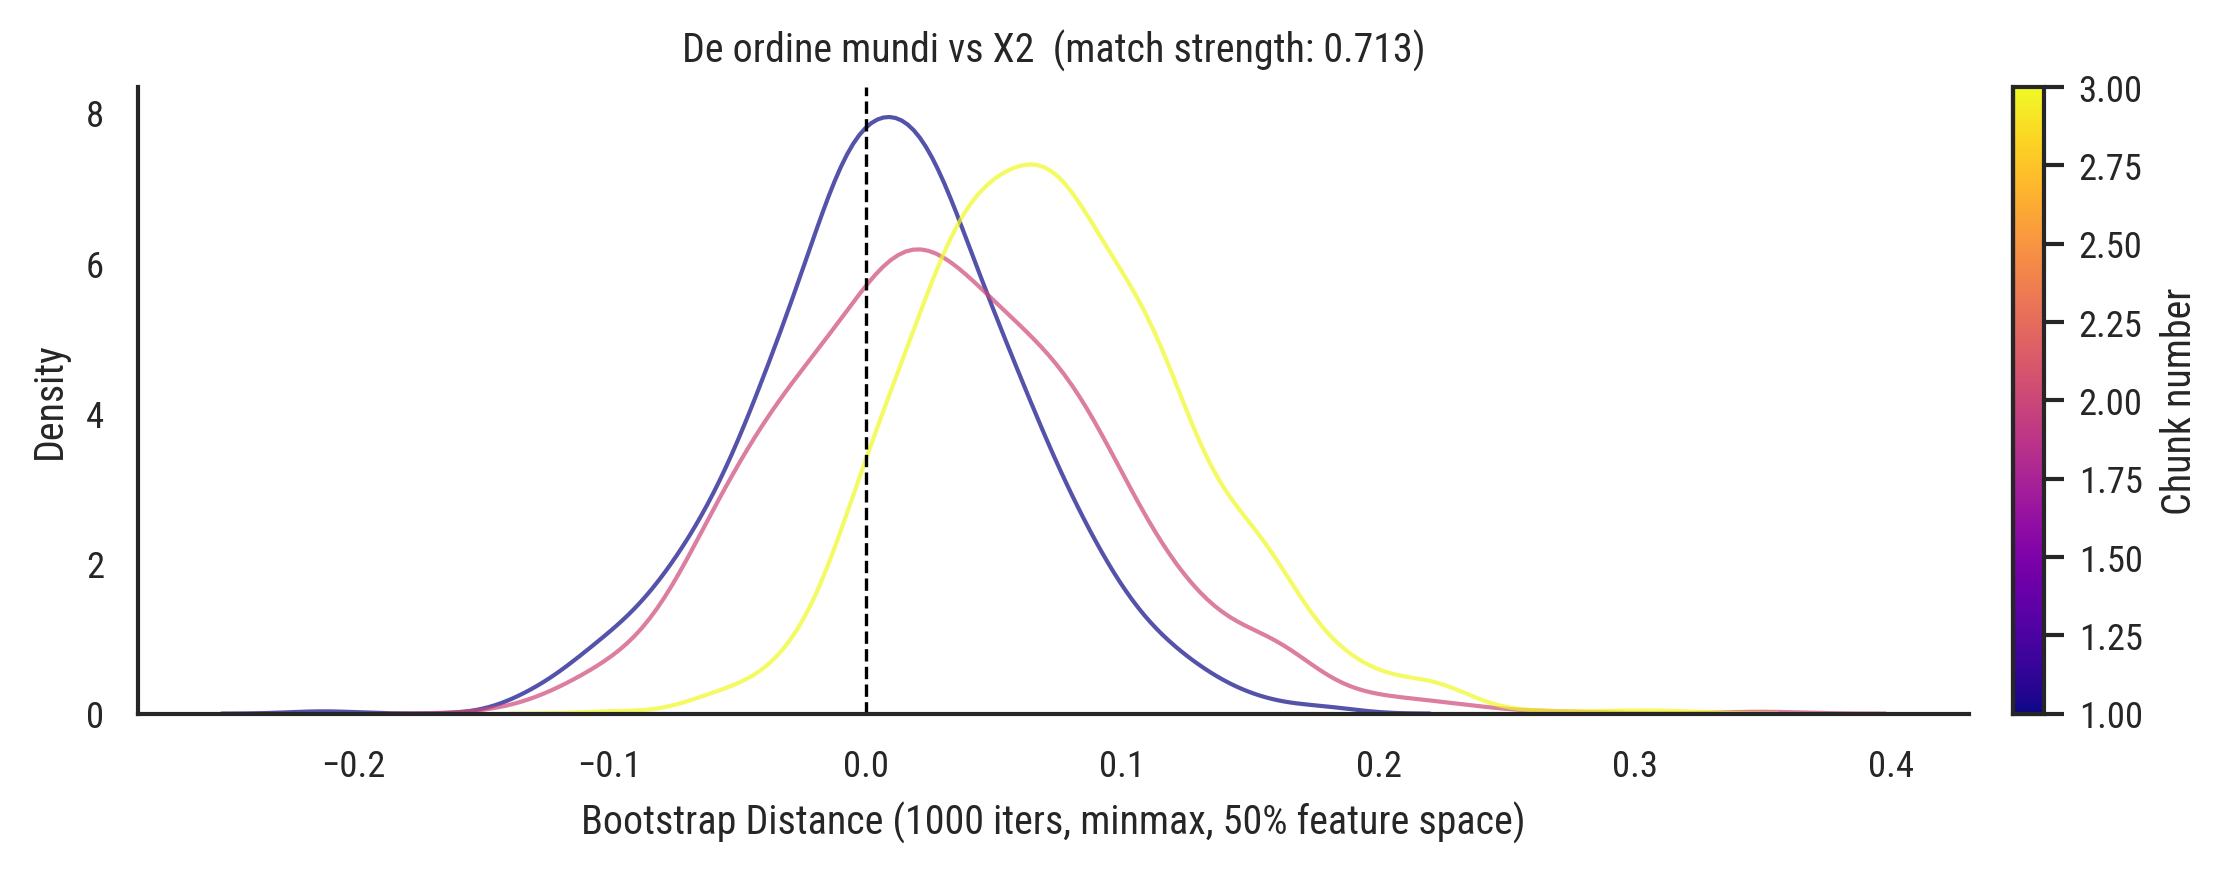

09/08/2026 01:45:36 [bdi:INFO] Predicting on 3 documents


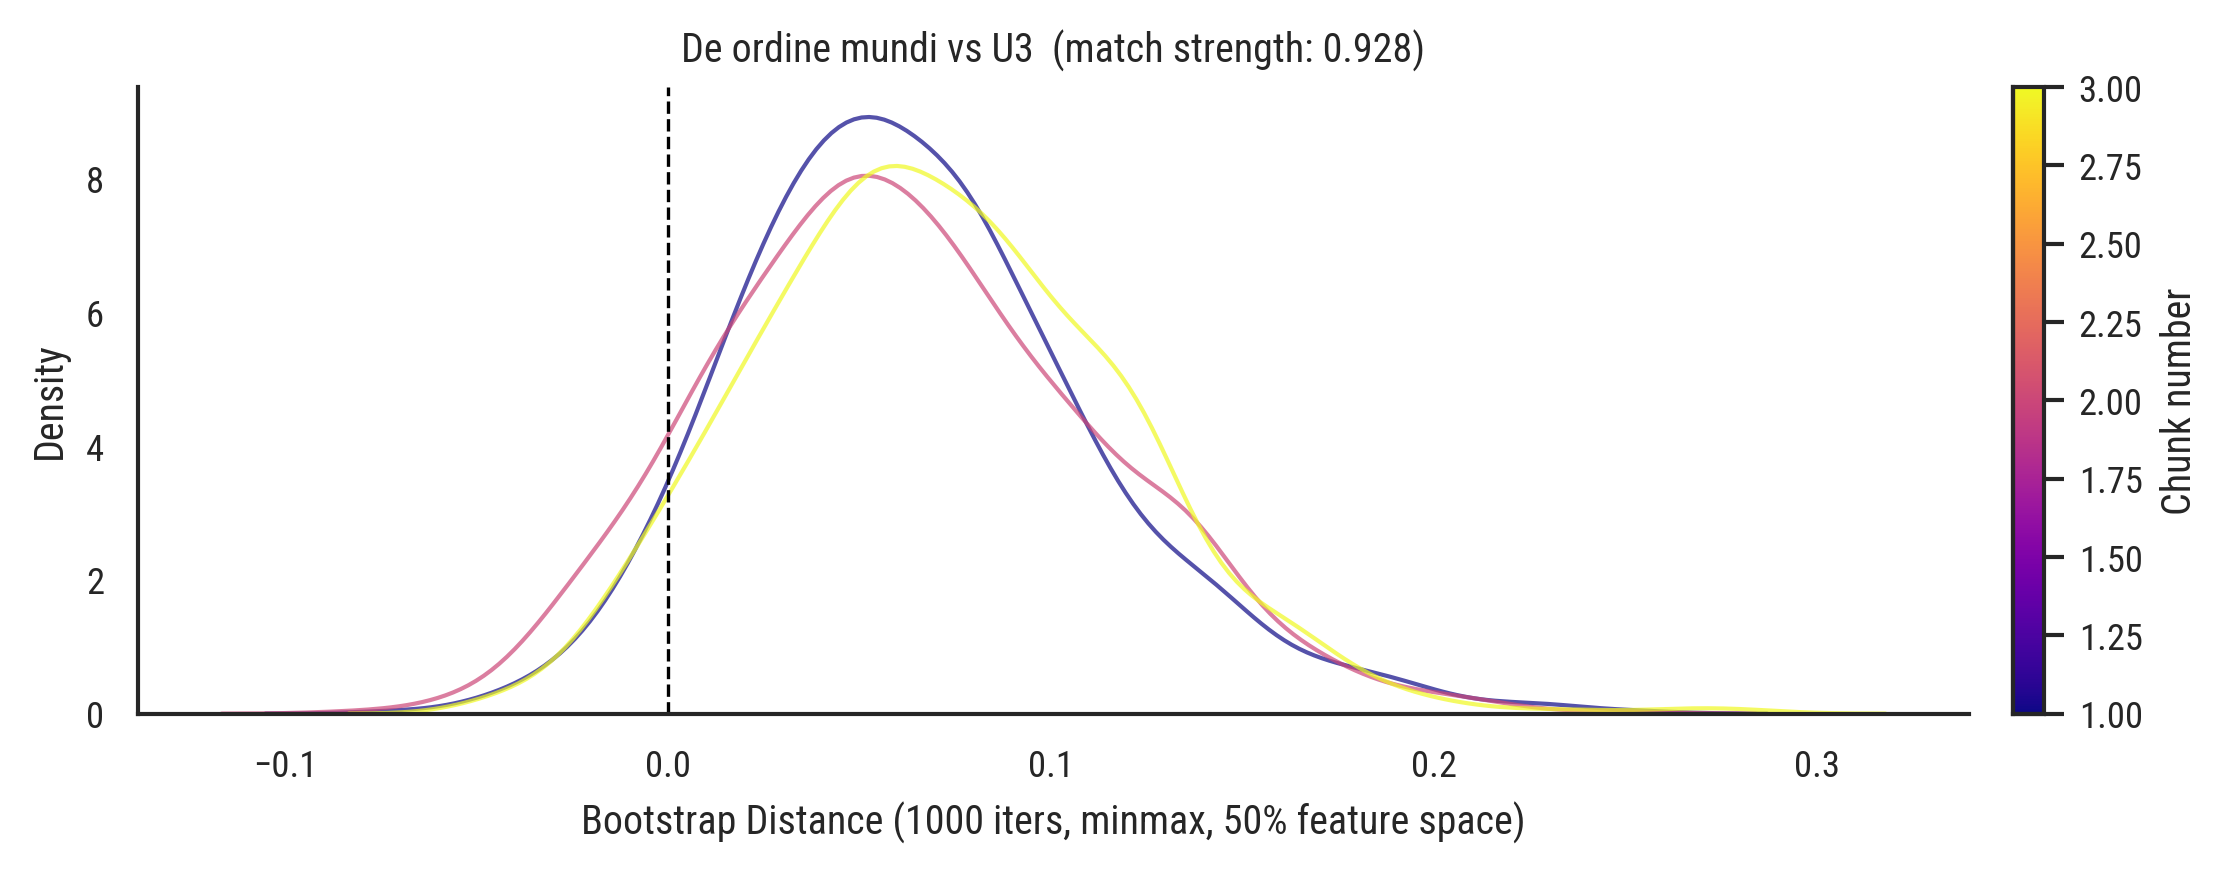

In [21]:
candidates = ["X2", "U3"]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)

for candidate in candidates:
    label_idx = label_encoder.transform([candidate])[0]
    bdi_mm.predict_proba(problem_X, [label_idx] * problem_X.shape[0])

    dist_df = pd.DataFrame(
        dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
    )

    mean_str = results[candidate]["mean"]
    fig, ax = plt.subplots(figsize=(8, 3))
    plot_kde_viridis(
        dist_df,
        poem_names,
        title=f"De ordine mundi vs {candidate}  (match strength: {mean_str:.3f})",
        xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
        ax=ax,
    )
    sns.despine()
    fig.tight_layout()
    plt.show()

## Feature Selection Variants

The previous analysis used all features. Here we test whether feature selection improves discrimination by comparing three strategies:
- **none**: use all features (baseline)
- **variance_threshold**: remove features with variance below a cutoff (standard approach — low-variance features are less discriminative)
- **fisher_ratio**: keep features with the highest ratio of between-class to within-class variance (ANOVA-style, directly targets discriminative power)

In [23]:
def select_features(
    X: pd.DataFrame,
    y: pd.Series | None = None,
    method: str = "none",
    **kwargs,
) -> pd.Index:
    """Select features (columns) from X based on the given method.

    Args:
        X: Feature DataFrame (samples × features).
        y: Class labels, required for 'fisher_ratio'.
        method: One of 'none', 'variance_threshold', 'fisher_ratio'.
        **kwargs:
            min_variance (float): For 'variance_threshold'.
                Remove features with variance below this value. Default 0.01.
            n_features (int): For 'fisher_ratio'. Keep top N by F-ratio. Default 20.

    Returns:
        pd.Index of selected column names.
    """
    if method == "none":
        return X.columns

    if method == "variance_threshold":
        min_var = kwargs.get("min_variance", 0.01)
        variances = X.var(axis=0)
        keep = variances >= min_var
        return X.columns[keep]

    if method == "fisher_ratio":
        if y is None:
            raise ValueError("fisher_ratio requires class labels (y).")
        n = kwargs.get("n_features", 20)
        classes = y.unique()
        overall_mean = X.mean(axis=0)
        between_var = pd.Series(0.0, index=X.columns)
        within_var = pd.Series(0.0, index=X.columns)
        for c in classes:
            mask = y == c
            n_c = mask.sum()
            class_mean = X.loc[mask].mean(axis=0)
            class_var = X.loc[mask].var(axis=0)
            between_var += n_c * (class_mean - overall_mean) ** 2
            within_var += (n_c - 1) * class_var
        # Avoid division by zero
        within_var = within_var.replace(0, np.nan)
        f_ratio = between_var / within_var
        f_ratio = f_ratio.fillna(0).sort_values(ascending=False)
        return f_ratio.head(n).index

    raise ValueError(
        f"Unknown method: {method}. Choose from 'none', 'variance_threshold', 'fisher_ratio'."
    )


# Quick sanity check
assert len(select_features(comparison_X, method="none")) == comparison_X.shape[1]
vt_cols = select_features(comparison_X, method="variance_threshold")
assert len(vt_cols) <= comparison_X.shape[1]
print(f"variance_threshold: {len(vt_cols)} / {comparison_X.shape[1]} features")
fr_cols = select_features(
    comparison_X, y=comparison_y, method="fisher_ratio", n_features=10
)
assert len(fr_cols) == 10
print("select_features() sanity checks passed.")

variance_threshold: 21 / 21 features
select_features() sanity checks passed.


In [24]:
# Run BDI for each feature selection method
variant_results = {}
rng2 = np.random.default_rng(42)

for method_name in ["none", "variance_threshold", "fisher_ratio"]:
    print(f"\n{'='*60}")
    print(f"Feature selection: {method_name}")
    print(f"{'='*60}")

    # Select features
    if method_name == "fisher_ratio":
        selected = select_features(
            comparison_X, y=comparison_y, method=method_name, n_features=38
        )
    elif method_name == "variance_threshold":
        selected = select_features(comparison_X, method=method_name, min_variance=0.05)
    else:
        selected = select_features(comparison_X, method=method_name)

    comp_X = comparison_X[selected].copy()
    prob_X = problem_X[selected].copy()
    print(f"  Features used: {len(selected)}")
    print(f"  Features Dropped: {set(comparison_X.columns) - set(selected)}")

    # Fit and predict
    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=2000,
        rnd_prop=0.35,
        random_state=rng2,
    )
    verifier.fit(comp_X, comparison_y)

    method_results = {}
    for int_label in sorted(set(comparison_y)):
        str_label = label_encoder.classes_[int_label]
        try:
            probas = verifier.predict_proba(prob_X, [int_label] * prob_X.shape[0])
            method_results[str_label] = {"mean": np.mean(probas), "std": np.std(probas)}
        except Exception as e:
            print(f"  Error for {str_label}: {e}")

    variant_results[method_name] = method_results
    # Show top 5
    top5 = sorted(method_results.items(), key=lambda x: x[1]["mean"], reverse=True)[:5]
    for author, vals in top5:
        print(f"  {author}: {vals['mean']:.4f} ± {vals['std']:.4f}")

09/08/2026 01:45:36 [bdi:INFO] Fitting on 656 documents...
09/08/2026 01:45:36 [bdi:INFO] Predicting on 3 documents



Feature selection: none
  Features used: 21
  Features Dropped: set()


09/08/2026 01:45:36 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:37 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:37 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:37 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:37 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:38 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:38 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:38 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:38 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:38 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:39 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:39 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:39 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:39 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:40 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:40 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:40 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:40 [bdi:INFO] 

  U3: 0.9272 ± 0.0203
  FB: 0.7357 ± 0.0267
  X2: 0.7198 ± 0.1655
  DC: 0.6515 ± 0.1290
  U11: 0.6357 ± 0.0847

Feature selection: variance_threshold
  Features used: 21
  Features Dropped: set()


09/08/2026 01:45:45 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:45 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:45 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:45 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:46 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:46 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:46 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:46 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:46 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:47 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:47 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:47 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:47 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:48 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:48 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:48 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:48 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:48 [bdi:INFO] 

  U3: 0.9225 ± 0.0194
  FB: 0.7392 ± 0.0204
  X2: 0.7282 ± 0.1532
  DC: 0.6613 ± 0.1061
  U11: 0.6433 ± 0.0980

Feature selection: fisher_ratio
  Features used: 21
  Features Dropped: set()


09/08/2026 01:45:53 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:53 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:53 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:54 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:54 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:54 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:54 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:55 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:55 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:55 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:55 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:55 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:56 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:56 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:56 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:56 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:56 [bdi:INFO] Predicting on 3 documents
09/08/2026 01:45:57 [bdi:INFO] 

  U3: 0.9203 ± 0.0186
  FB: 0.7388 ± 0.0325
  X2: 0.7142 ± 0.1593
  DC: 0.6648 ± 0.1265
  U11: 0.6443 ± 0.0961


### Variant Comparison

Compare how the three feature selection strategies affect the top-ranked candidates.

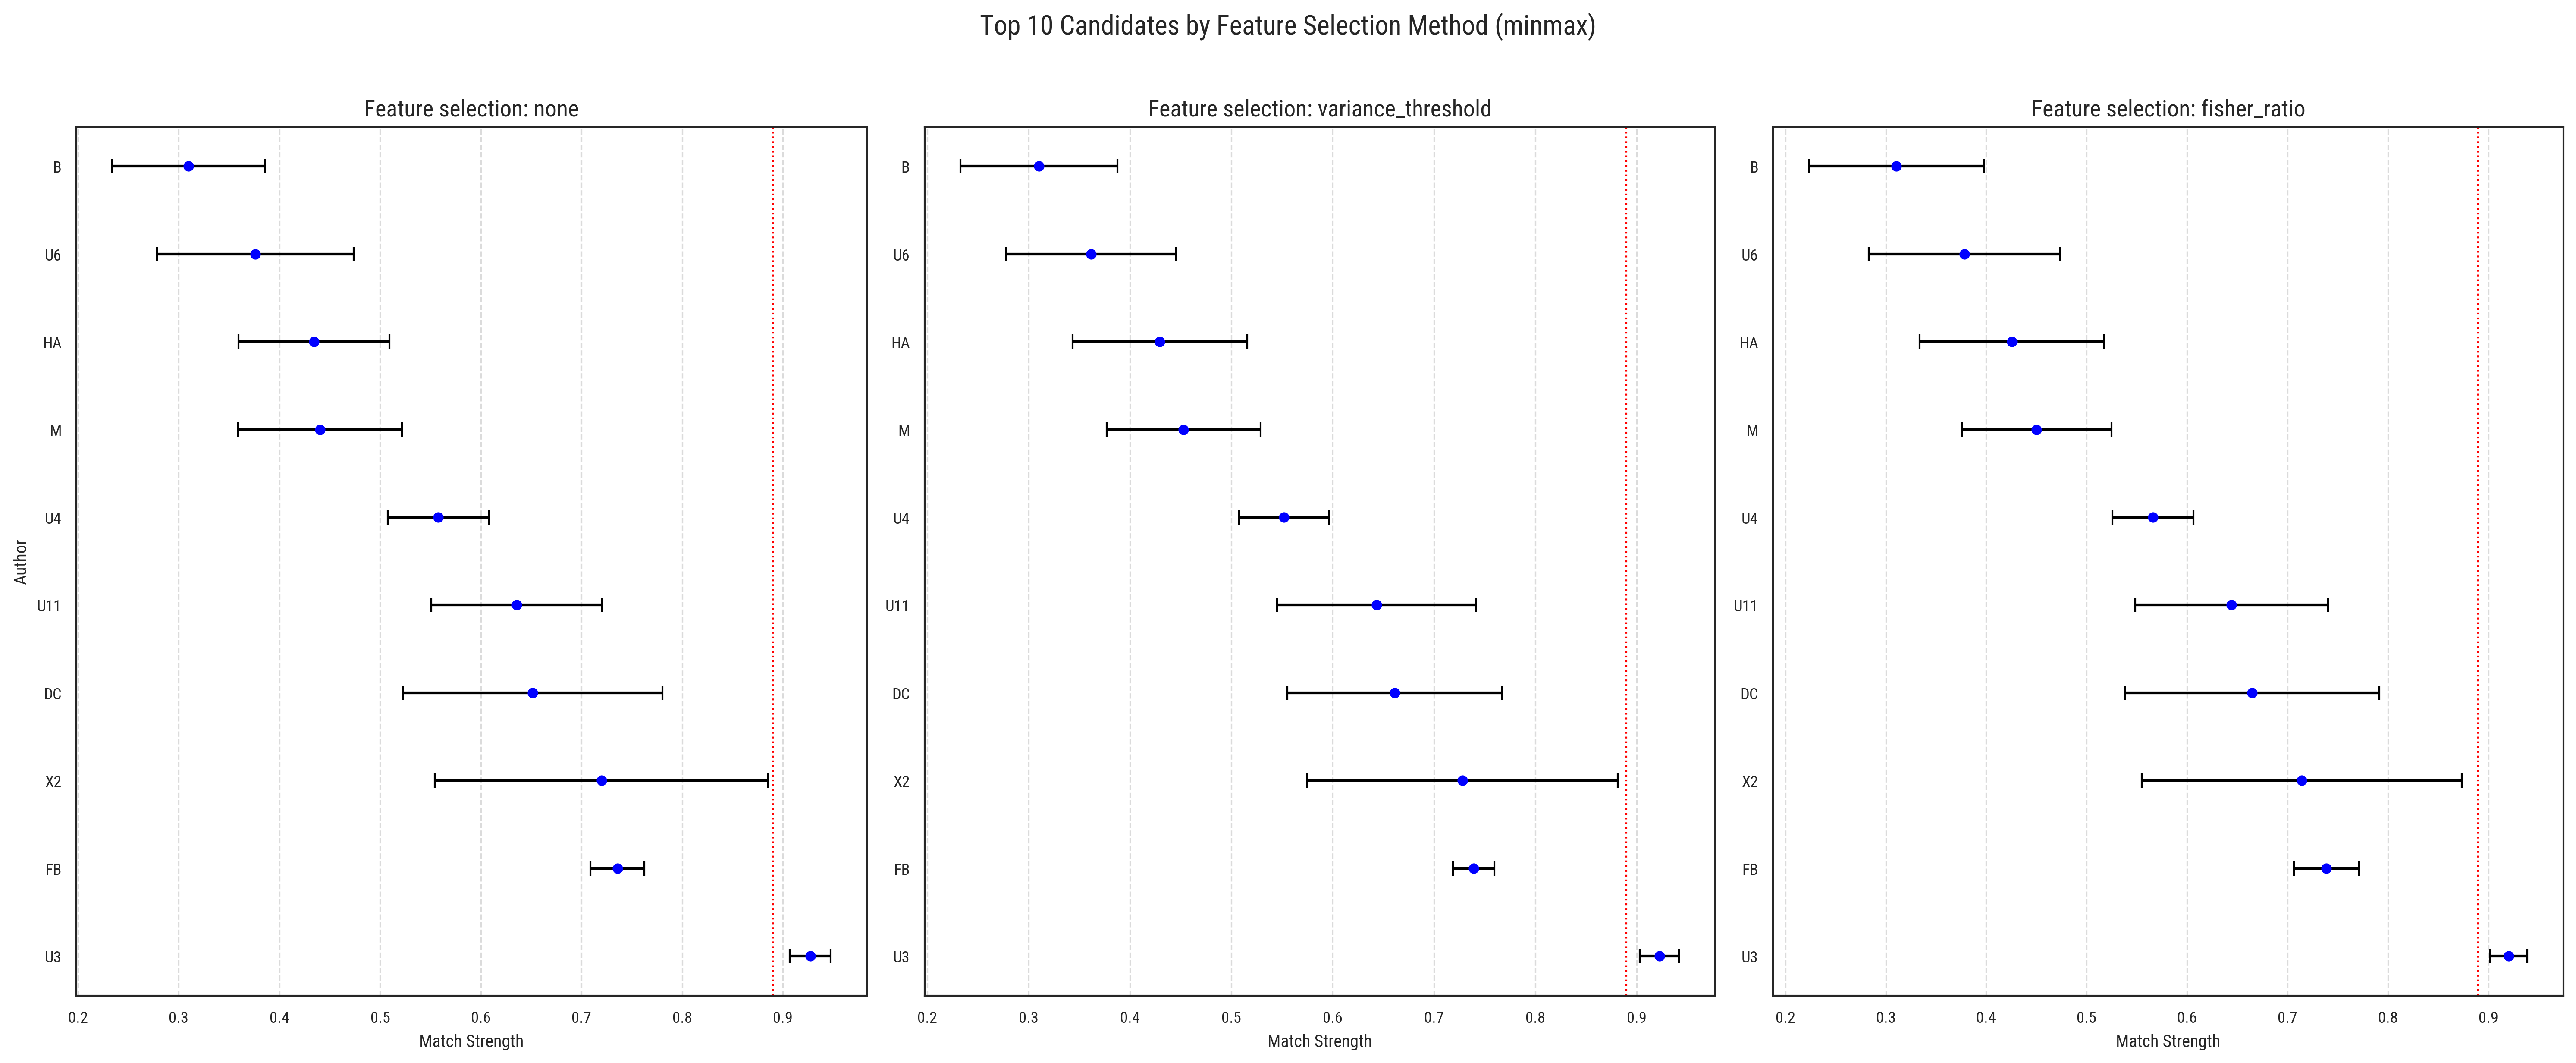

In [26]:
# Show top 10 for each variant side by side
fig, axes = plt.subplots(1, 3, figsize=(20, 8), sharey=False)

for ax, (method_name, res) in zip(axes, variant_results.items()):
    sorted_r = sorted(res.items(), key=lambda x: x[1]["mean"], reverse=True)[:10]
    labels_m = [r[0] for r in sorted_r]
    means_m = [r[1]["mean"] for r in sorted_r]
    stds_m = [r[1]["std"] for r in sorted_r]

    ax.errorbar(
        means_m,
        labels_m,
        xerr=stds_m,
        fmt="o",
        color="blue",
        ecolor="black",
        elinewidth=1.5,
        capsize=4,
    )
    ax.set_title(f"Feature selection: {method_name}", fontsize=13)
    ax.set_xlabel("Match Strength")
    ax.axvline(0.89, color="red", linestyle=":", linewidth=1)
    ax.grid(axis="x", linestyle="--", alpha=0.7)

axes[0].set_ylabel("Author")
fig.suptitle(
    "Top 10 Candidates by Feature Selection Method (minmax)", fontsize=15, y=1.02
)
fig.tight_layout()
plt.savefig("feature_selection_comparison.png", dpi=300, bbox_inches="tight")
plt.show()